# AI/ML CE-1: Disease Prediction from Symptoms

## Project Overview
This project analyzes symptom data and prepares it for machine-learning-based disease prediction. Symptoms are represented as input features and the diagnosed disease is used as the target label.

## Problem Statement
Identifying a likely disease from a patient's symptoms can be difficult when many diseases share similar symptoms. This project uses data analysis and machine learning preparation techniques to discover symptom patterns and prepare a classification dataset for disease prediction.

## Objectives
1. Collect and inspect a suitable symptom-disease dataset.
2. Clean missing, duplicate, and inconsistent records.
3. Transform symptom data into machine-learning-ready features.
4. Explore symptom and disease distributions using meaningful visualizations.
5. Define the feature matrix and target label for future model development.

## Dataset Description
The project uses the symptom-disease dataset in `Data/`. The raw dataset contains 4,920 records and up to 17 symptom fields per disease record. `Training.csv` is a binary, one-hot encoded dataset with 132 symptom features and one `prognosis` target column. `Testing.csv` contains 41 held-out records for final evaluation. The `MasterData/` files provide disease descriptions, precautions, and symptom severity information.

## CE-1 Scope
This notebook covers data loading, cleaning, missing-value treatment, duplicate inspection, transformation, exploratory analysis, feature preparation, and baseline classification evaluation. It is not intended to replace professional medical diagnosis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the raw symptom dataset without assuming a header row
df_raw = pd.read_csv('Data/dataset.csv', header=None)
df_raw = df_raw.dropna(how='all').reset_index(drop=True)
df_raw.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Set clean column headers
cols = ['Disease'] + [f'Symptom_{i}' for i in range(1, 18)]
df_raw.columns = cols[:df_raw.shape[1]]

# Display first 5 rows with proper headers
df_raw.head()

,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# 1. DATA CLEANING: remove records where the disease target is missing
df_raw = df_raw.dropna(subset=['Disease']).copy()

# 2. DATA TRANSFORMATION: load the supplied one-hot encoded datasets
df_train = pd.read_csv('Data/Training.csv')
df_test = pd.read_csv('Data/Testing.csv')

print('Missing values in target:', df_raw['Disease'].isnull().sum())
print('Raw dataset shape:', df_raw.shape)
print('Training dataset shape:', df_train.shape)
print('Testing dataset shape:', df_test.shape)
print('Duplicate training rows:', df_train.duplicated().sum())
print('Duplicate testing rows:', df_test.duplicated().sum())

# The training data is already binary encoded: symptom columns contain 0 or 1.
df_train.head()

Missing values in target: 0
Raw dataset shape: (4920, 18)
Training dataset shape: (4920, 133)
Testing dataset shape: (41, 133)
Duplicate training rows: 4616
Duplicate testing rows: 0


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


In [5]:
print(df_raw.isnull().sum().sum())  # Total missing values check

46992


In [6]:
# ==========================================
# Handling Structural NaNs in Raw Dataset
# ==========================================

# Missing symptom entries mean that no additional symptom was recorded.
df_cleaned_raw = df_raw.fillna('None')

print("Null values after filling structural gaps:", df_cleaned_raw.isnull().sum().sum())
print("Duplicate raw records:", df_cleaned_raw.duplicated().sum())
df_cleaned_raw.head(3)

Null values after filling structural gaps: 0
Duplicate raw records: 4616


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None


In [7]:
# Display the cleaned raw dataframe to confirm NaNs are replaced
df_cleaned_raw.head(50)

,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
3,Fungal infection,itching,skin_rash,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,None,None,None,None,None,None,None,None,None,None,None,None,None,None
5,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
6,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
7,Fungal infection,itching,skin_rash,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None,None
8,Fungal infection,itching,skin_rash,nodal_skin_eruptions,None,None,None,None,None,None,None,None,None,None,None,None,None,None
9,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,None,None,None,None,None,None,None,None,None,None,None,None,None


In [8]:
# Basic Exploratory Inspection Commands for Viva Demonstration
print("--- 1. Dataset Shape (Rows & Columns) ---")
print(df_train.shape)

print("\n--- 2. Dataset Information & Data Types ---")
print(df_train.info())

print("\n--- 3. Checking for Missing Values Across All Columns ---")
print(df_train.isnull().sum().sum())  # Total missing values check

print("\n--- 4. First 3 Rows Preview ---")
display(df_train.head(3))

--- 1. Dataset Shape (Rows & Columns) ---
(4920, 133)

--- 2. Dataset Information & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Columns: 133 entries, itching to prognosis
dtypes: int64(132), object(1)
memory usage: 5.0+ MB
None

--- 3. Checking for Missing Values Across All Columns ---
0

--- 4. First 3 Rows Preview ---


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


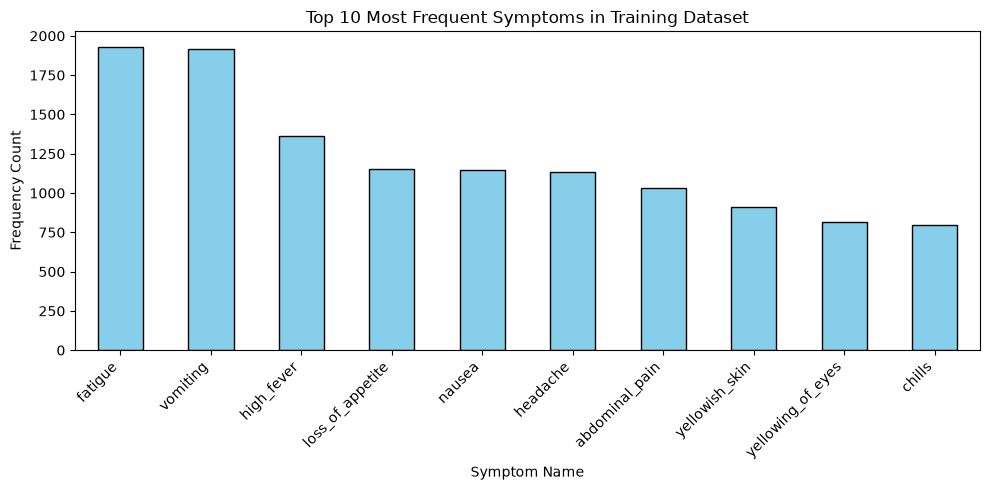

Observation: The most frequent symptoms occur across many disease records and may be useful baseline predictors.


In [9]:
# EXPLORATORY DATA ANALYSIS: Top 10 Most Frequent Symptoms
symptom_columns = df_train.drop(columns=['prognosis'])
symptom_counts = symptom_columns.sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
symptom_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Top 10 Most Frequent Symptoms in Training Dataset')
plt.xlabel('Symptom Name')
plt.ylabel('Frequency Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print('Observation: The most frequent symptoms occur across many disease records and may be useful baseline predictors.')

In [10]:
# ==========================================
# 6. FEATURE SELECTION & BASELINE MODEL
# ==========================================
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Use the supplied Testing.csv as an independent held-out test set.
feature_columns = [column for column in df_train.columns if column != 'prognosis']
df_train_clean = df_train.drop_duplicates().reset_index(drop=True)

X_train = df_train_clean[feature_columns]
y_train = df_train_clean['prognosis']
X_test = df_test[feature_columns]
y_test = df_test['prognosis']

print('Selected symptom features:', len(feature_columns))
print('Training rows after duplicate removal:', len(X_train))
print('Independent testing rows:', len(X_test))

# Decision trees use binary symptom features directly; scaling is unnecessary.
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Model Accuracy Score:', accuracy_score(y_test, y_pred) * 100, '%')

Selected symptom features: 132
Training rows after duplicate removal: 304
Independent testing rows: 41
Model Accuracy Score: 100.0 %


In [11]:
# ==========================================
# 7. PRE-PROCESSING VERIFICATION
# ==========================================
# Training.csv already contains one-hot/binary encoded symptom features.
encoded_values = set(df_train[feature_columns].stack().unique())
print('Unique values in encoded symptom features:', sorted(encoded_values))
print('Encoding verification:', encoded_values.issubset({0, 1}))

Unique values in encoded symptom features: [np.int64(0), np.int64(1)]
Encoding verification: True


In [12]:
# ==========================================
# 7. MODEL EVALUATION
# ==========================================
print('--- Classification Report on Independent Testing.csv ---')
print(classification_report(y_test, y_pred, zero_division=0))

--- Classification Report on Independent Testing.csv ---
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         1
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         1
                                Allergy       1.00      1.00      1.00         1
                              Arthritis       1.00      1.00      1.00         1
                       Bronchial Asthma       1.00      1.00      1.00         1
                   Cervical spondylosis       1.00      1.00      1.00         1
                            Chicken pox       1.00      1.00      1.00         1
                    Chronic cholestasis       1.00      1.00      1.00         1
                            Common Cold       1.00 

--- Top 8 Diseases Sample Count Summary ---
prognosis
Fungal infection       120
Allergy                120
GERD                   120
Chronic cholestasis    120
Drug Reaction          120
Peptic ulcer diseae    120
AIDS                   120
Diabetes               120
Name: count, dtype: int64


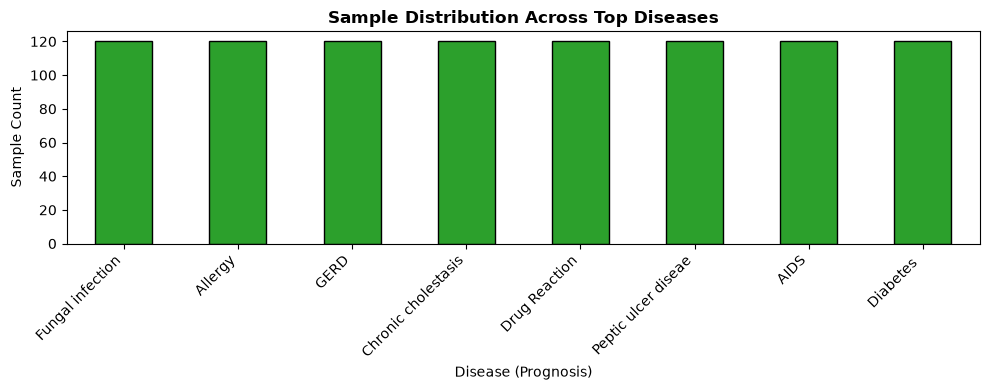

Observation: This chart shows which disease classes have the most training examples and helps identify class-balance concerns.


In [13]:
# ==========================================
# 8. ADVANCED PANDAS OPERATIONS & EXTRA VISUALIZATION
# ==========================================

disease_counts = df_train['prognosis'].value_counts().head(8)
print('--- Top 8 Diseases Sample Count Summary ---')
print(disease_counts)

plt.figure(figsize=(10, 4))
disease_counts.plot(kind='bar', color='#2ca02c', edgecolor='black')
plt.title('Sample Distribution Across Top Diseases', fontsize=12, fontweight='bold')
plt.xlabel('Disease (Prognosis)', fontsize=10)
plt.ylabel('Sample Count', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print('Observation: This chart shows which disease classes have the most training examples and helps identify class-balance concerns.')

## Conclusion
The symptom dataset was inspected, cleaned, transformed into binary machine-learning features, explored visually, and evaluated with a baseline Decision Tree classifier. Duplicate training records were identified and removed before model fitting, and the supplied testing file was used as an independent evaluation set.

## Project Planning and Future Scope
- Compare Decision Tree performance with Random Forest, Support Vector Machine, and other suitable classifiers.
- Use cross-validation and confusion matrices for more reliable evaluation.
- Integrate the disease-description, precaution, and severity master data files.
- Build a simple user interface for entering symptoms and displaying a predicted disease with a clear medical disclaimer.
- Validate the system with a larger, clinically reviewed dataset before any real-world use.

